<h1 style="text-align: center">Property Listings in Kuala Lumpur</h1>
<br>
<img src="assets\kuala_lumpur.jpg" width="450px">
<br>

<h1>1. Introduction</h1>
<p>The dataset was originally scraped and uploaded to Kaggle. The version of the dataset we are working with is a sample of 32,308 data points,<br> a less-cleaned version of the data.</p>
<p>The data dictionary provided with data is as follows:
<ul>
<li>Location - Where the property is located.</li>
<li>Price - Price of the property.</li>
<li>Rooms - Number of rooms.</li>
<li>Bathrooms - Number of bathrooms.</li>
<li>Car Parks - Number of car parking slot.</li>
<li>Property Type - Property type such as bungalow, condominium and many more.</li>
<li>Size - Area size of the property.</li>
<li>Furnishing - Either the property is fully furnished or partially furnished or unfurnished.</li>

<p>The aim of this project is to clean the data and analyze the included used property listings.</p>

<h1>2. Preparing the Dataset</h1>
<p>Importing the libraries so that we will be able to use them for the purpose of analyzation and visualization</p>

In [1]:
# Import all the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Import the dataset
property_kl = pd.read_csv('assets\property_kl.csv')

In [3]:
# Show the basic info of the dataset
property_kl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32309 entries, 0 to 32308
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Location       32308 non-null  object
 1   Price          32309 non-null  int64 
 2   Rooms          32309 non-null  object
 3   Bathrooms      32309 non-null  int64 
 4   Car Parks      32309 non-null  int64 
 5   Property Type  32309 non-null  object
 6   Size           32309 non-null  object
 7   Furnishing     32309 non-null  object
dtypes: int64(3), object(5)
memory usage: 2.0+ MB


In [4]:
# Print the first five rows of the dataset
property_kl.head()

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Size,Furnishing
0,Dutamas,4900000,3,3,1,Condominium (Intermediate),Built-up : 1 sq. ft.,Partly Furnished
1,Bangsar,780000,3,2,1,1-sty Terrace/Link House (Intermediate),Built-up : 1000 sq. ft.,Partly Furnished
2,Bukit Tunku (Kenny Hills),430000,4,3,1,1-sty Terrace/Link House (Intermediate),Built-up : 1000 sq. ft.,Fully Furnished
3,Bukit Jalil,1880000,2,6,1,2.5-sty Terrace/Link House (Intermediate),Built-up : 1000 sq. ft.,Partly Furnished
4,KLCC,1315000,3,2,1,2-sty Terrace/Link House,Built-up : 1000 sq. ft.,Partly Furnished


<h1>3. Data Cleaning and Data Standardization</h1>
<p>Dirty data can produce inaccurate results and therefore, we need to clean the data before we can analyse them. This includes removing any duplicate rows, dropping irrelevent columns and handling missing data</p>

In [5]:
# Display any rows containing null value
property_kl[property_kl.isna().any(axis=1)]

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Size,Furnishing
5561,NaN,1000000,4,5,2,Serviced Residence,Built-up : 1250 sq. ft.,Fully Furnished


In [6]:
# Cleaning and standardizing the dataset

# Drop any rows containing null values
property_kl = property_kl.dropna()

# Standardizing all the value with proper naming convention
property_kl['Location'] = property_kl.Location.str.replace('Klcc', 'KLCC')
property_kl['Location'] = property_kl.Location.str.replace('SANTUARI PARK PANTAI', 'Santuari Park Pantai')
property_kl['Location'] = property_kl.Location.str.replace('SEMARAK', 'Semarak')
property_kl['Location'] = property_kl.Location.str.replace('Taman Yarl UOG', 'Taman Yarl OUG')
property_kl['Location'] = property_kl.Location.str.replace('cyberjaya', 'Cyberjaya')
property_kl['Location'] = property_kl.Location.str.replace('taman cheras perdana', 'Taman Cheras Perdana')

# Drop property located in Singapore
property_kl = property_kl[~property_kl.Location.str.contains("Singapore")]

<h1>4. Exploring the Data</h1>
<p>Data exploration is the initial step in data analysis, where we explore a large data set in an unstructured way to uncover initial patterns, characteristics, and points of interest. This process isn’t meant to reveal every bit of information a dataset holds, but rather to help create a broad picture of important trends and major points to study in greater detail.</p>
<p>This process makes deeper analysis easier because it can help target future searches and begin the process of excluding irrelevant data points and search paths that may turn up no results. More importantly, it helps build a familiarity with the existing information that makes finding better answers much simpler.</p>

In [7]:
# Group all rows by location
property_kl.groupby(by=["Location"], dropna=False).count()

,Price,Rooms,Bathrooms,Car Parks,Property Type,Size,Furnishing
Location,,,,,,,
ADIVA Desa ParkCity,1,1,1,1,1,1,1
Alam Damai,1,1,1,1,1,1,1
Ampang,706,706,706,706,706,706,706
Ampang Hilir,362,362,362,362,362,362,362
Bandar Damai Perdana,101,101,101,101,101,101,101
...,...,...,...,...,...,...,...
Titiwangsa,107,107,107,107,107,107,107
U-THANT,1,1,1,1,1,1,1
Ukay Heights,1,1,1,1,1,1,1


In [8]:
# Group all rows based on property type
property_kl.groupby(by=["Property Type"], dropna=False).count()

,Location,Price,Rooms,Bathrooms,Car Parks,Size,Furnishing
Property Type,,,,,,,
1-sty Terrace/Link House,110,110,110,110,110,110,110
1-sty Terrace/Link House (Corner),59,59,59,59,59,59,59
1-sty Terrace/Link House (EndLot),21,21,21,21,21,21,21
1-sty Terrace/Link House (Intermediate),304,304,304,304,304,304,304
1.5-sty Terrace/Link House,15,15,15,15,15,15,15
...,...,...,...,...,...,...,...
Townhouse,87,87,87,87,87,87,87
Townhouse (Corner),25,25,25,25,25,25,25
Townhouse (Duplex),4,4,4,4,4,4,4


In [9]:
# Group all rows based on size
property_kl.groupby(by=["Size"], dropna=False).count()

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Furnishing
Size,,,,,,,
Built-up : 1 sq. ft.,1,1,1,1,1,1,1
Built-up : 1000 sq. ft.,145,145,145,145,145,145,145
Built-up : 10000 sq. ft.,3,3,3,3,3,3,3
Built-up : 1001 sq. ft.,44,44,44,44,44,44,44
Built-up : 1002 sq. ft.,5,5,5,5,5,5,5
...,...,...,...,...,...,...,...
Land area : 9978 sq. ft.,10,10,10,10,10,10,10
Land area : 9979 sq. ft.,6,6,6,6,6,6,6
Land area : 998 sq. ft.,1,1,1,1,1,1,1


In [10]:
# Group all rows based on furnishing
property_kl.groupby(by=["Furnishing"], dropna=False).count()

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Size
Furnishing,,,,,,,
Fully Furnished,9601,9601,9601,9601,9601,9601,9601
Partly Furnished,18412,18412,18412,18412,18412,18412,18412
Unfurnished,3857,3857,3857,3857,3857,3857,3857
Unknown,437,437,437,437,437,437,437


In [11]:
# Count number of property according to the property type
property_kl.groupby(["Property Type"]).size().reset_index(name='counts').sort_values(by=["counts"], ascending=False).head(10)

,Property Type,counts
52,Condominium,6989
75,Serviced Residence,4138
53,Condominium (Corner),3542
56,Condominium (Intermediate),3127
79,Serviced Residence (Intermediate),1884
12,2-sty Terrace/Link House (Intermediate),1484
76,Serviced Residence (Corner),1442
42,Bungalow,1042
23,3-sty Terrace/Link House (Intermediate),602
8,2-sty Terrace/Link House,591


In [12]:
# Count number of property according to the location
property_kl.groupby(["Location"]).size().reset_index(name='Count').sort_values(by=["Count"], ascending=False).head(10)

,Location,Count
47,Mont Kiara,3646
41,KLCC,3044
19,Cheras,2738
14,Bukit Jalil,1592
34,Jalan Klang Lama (Old Klang Road),1573
64,Setapak,1513
42,Kepong,1469
8,Bangsar,1226
26,Desa ParkCity,1056
24,Damansara Heights,883


In [13]:
# Sort and display the top ten most expensive property in Kuala Lumpur
property_kl.sort_values(by='Price', ascending=False).head(10)

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Size,Furnishing
15935,Mont Kiara,1980000000,3,8,1,Bungalow (Intermediate),Built-up : 3126 sq. ft.,Fully Furnished
12276,Jalan Klang Lama (Old Klang Road),1600000000,6,2,2,Serviced Residence,Built-up : 1878 sq. ft.,Fully Furnished
32100,Seputeh,1123000000,4,2,2,Bungalow,Land area : 950 sq. ft.,Partly Furnished
790,Bukit Jalil,339768000,3,2,1,Condominium (Intermediate),Built-up : 1023 sq. ft.,Fully Furnished
4848,City Centre,262666800,2,2,2,Condominium (Intermediate),Built-up : 1215 sq. ft.,Partly Furnished
21874,Sri Hartamas,216000000,3,2,2,Semi-detached House (Corner),Built-up : 821 sq. ft.,Fully Furnished
23824,Damansara,180000000,3,3,2,Serviced Residence (Intermediate),Built-up : 916 sq. ft.,Unfurnished
28137,Cheras,164000000,5,3,4,Condominium,Land area : 2040 sq. ft.,Fully Furnished
15704,Dutamas,164000000,5,2,2,Condominium,Built-up : 3000 sq. ft.,Partly Furnished
1701,Bukit Tunku (Kenny Hills),146000000,3,2,1,Bungalow (Corner),Built-up : 1066 sq. ft.,Partly Furnished


In [14]:
# Separate the dataset into three location: Mont Kiara, KLCC and Cheras
montkiara_df = property_kl[property_kl.Location.str.contains("Mont Kiara")]
klcc_df = property_kl[property_kl.Location.str.contains("KLCC")]
cheras_df = property_kl[property_kl.Location.str.contains("Cheras")]

In [15]:
# Display first ten rows from Mont Kiara dataset
montkiara_df.head(10)

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Size,Furnishing
10,Mont Kiara,280000,6,2,2,2-sty Terrace/Link House (Intermediate),Built-up : 1000 sq. ft.,Partly Furnished
26,Mont Kiara,2400000,4,2,4,Bungalow,Built-up : 1000 sq. ft.,Partly Furnished
33,Mont Kiara,798000,3,2,2,Condominium,Built-up : 1000 sq. ft.,Partly Furnished
53,Mont Kiara,2100000,2,6,2,Condominium,Built-up : 1000 sq. ft.,Partly Furnished
62,Mont Kiara,2400000,4,2,1,Condominium (Corner),Built-up : 1000 sq. ft.,Fully Furnished
68,Mont Kiara,2368600,4,6,2,Condominium (Corner),Built-up : 1000 sq. ft.,Unfurnished
78,Mont Kiara,925000,5,2,1,Condominium (Intermediate),Built-up : 1000 sq. ft.,Partly Furnished
86,Mont Kiara,1400000,4,5,5,Condominium (Intermediate),Built-up : 1000 sq. ft.,Partly Furnished
93,Mont Kiara,640000,3,2,2,Condominium (Penthouse),Built-up : 1000 sq. ft.,Unfurnished
98,Mont Kiara,2500000,2,2,2,Semi-detached House (Corner),Built-up : 1000 sq. ft.,Partly Furnished


In [16]:
# Remove rooms labelled "Studio" from three datasets
montkiara_df = montkiara_df[~montkiara_df.Rooms.str.contains("Studio")]
klcc_df = klcc_df[~klcc_df.Rooms.str.contains("Studio")]
cheras_df = cheras_df[~cheras_df.Rooms.str.contains("Studio")]

In [17]:
# Most reasonable price for property in Mont Kiara based on property type, price and number of rooms
montkiara_df[['Property Type', 'Price', 'Rooms']].groupby(['Property Type', 'Price'], as_index=False).min().sort_values(by='Rooms', ascending=False).head(10)

,Property Type,Price,Rooms
1744,Semi-detached House (Corner),1750000,9
35,1-sty Terrace/Link House (Intermediate),2150000,9
429,Apartment,1200000,9
672,Bungalow (Intermediate),4800000,8
346,3-sty Terrace/Link House (Intermediate),590000,8
404,4-sty Terrace/Link House (Corner),2660000,8
1792,Semi-detached House (Intermediate),1020000,8
1623,Flat,358000,8
20,1-sty Terrace/Link House (EndLot),648000,8
1084,Condominium (Corner),2800,8


In [18]:
# Most reasonable price for property in KLCC based on property type, price and number of rooms
klcc_df[['Property Type', 'Price', 'Rooms']].groupby(['Property Type', 'Price'], as_index=False).min().sort_values(by='Rooms', ascending=False).head(10)

,Property Type,Price,Rooms
1838,Serviced Residence (Corner),1240000,9
361,Apartment,300000,9
1902,Serviced Residence (Duplex),2100000,9
983,Condominium (Corner),785000,9
1072,Condominium (Corner),4000000,9
978,Condominium (Corner),725000,8
609,Condominium,198000,8
962,Condominium (Corner),598000,8
793,Condominium,1828000,8
1526,Serviced Residence,318000,8


In [19]:
# Most reasonable price for property in Cheras based on property type, price and number of rooms
cheras_df[['Property Type', 'Price', 'Rooms']].groupby(['Property Type', 'Price'], as_index=False).min().sort_values(by='Rooms', ascending=False).head(10)

,Property Type,Price,Rooms
325,3-sty Terrace/Link House (Intermediate),1100000,9
1898,Serviced Residence (Intermediate),1950000,9
1641,Serviced Residence,1880000,9
1323,Condominium (Intermediate),5200000,8
909,Condominium (Corner),320000,8
1683,Serviced Residence,5878950,8
864,Condominium,5500000,8
1174,Condominium (Intermediate),403000,8
1234,Condominium (Intermediate),975000,8
232,2.5-sty Terrace/Link House,2420000,8


In [20]:
top_property = property_kl["Location"].value_counts(normalize=True).sort_values(ascending = False).head(20).index
top_property

Index(['Mont Kiara ', 'KLCC ', 'Cheras ', 'Bukit Jalil ',
       'Jalan Klang Lama (Old Klang Road) ', 'Setapak ', 'Kepong ', 'Bangsar ',
       'Desa ParkCity ', 'Damansara Heights ', 'Dutamas ', 'Ampang ',
       'Sentul ', 'Taman Tun Dr Ismail ', 'Sungai Besi ', 'Sri Hartamas ',
       'Taman Desa ', 'Wangsa Maju ', 'Segambut ', 'Bukit Bintang '],
      dtype='object')

In [21]:
#get the mean price for each property in location
mean_prices = {}

for Locations in top_property:
    selected_property = property_kl[property_kl['Location'] == Locations] 
    price_mean = selected_property['Price'].mean() #calculate the mean of the `price` property based on location
    mean_prices[Locations] = int(price_mean)  
    #print(price_mean)
    
sorted(mean_prices.items(), key=lambda kv: kv[1],reverse=True)

[('Jalan Klang Lama (Old Klang Road) ', 3039157),
 ('Mont Kiara ', 2621287),
 ('Damansara Heights ', 2373115),
 ('Desa ParkCity ', 2257064),
 ('Sri Hartamas ', 2169788),
 ('Wangsa Maju ', 2065018),
 ('Bukit Bintang ', 2047133),
 ('Bukit Jalil ', 2027691),
 ('Kepong ', 1959088),
 ('Dutamas ', 1957308),
 ('Cheras ', 1940739),
 ('Bangsar ', 1855036),
 ('Sungai Besi ', 1846741),
 ('Taman Tun Dr Ismail ', 1796524),
 ('KLCC ', 1795744),
 ('Sentul ', 1775043),
 ('Setapak ', 1728400),
 ('Taman Desa ', 1706904),
 ('Segambut ', 1650671),
 ('Ampang ', 1637807)]

In [22]:
#get the mean bathroom for property based on the location
mean_bathroom = {}

for Locations in top_property:
    selected_property = property_kl[property_kl['Location'] == Locations] 
    bathroom_mean = selected_property['Bathrooms'].mean() #calculate the mean for bathroom inside property based on location
    mean_bathroom[Locations] = int(bathroom_mean)  
    #print(bathroom_mean)
    
sorted(mean_bathroom.items(), key=lambda kv: kv[1],reverse=True)

[('Mont Kiara ', 3),
 ('KLCC ', 3),
 ('Cheras ', 3),
 ('Bukit Jalil ', 3),
 ('Jalan Klang Lama (Old Klang Road) ', 3),
 ('Setapak ', 3),
 ('Kepong ', 3),
 ('Bangsar ', 3),
 ('Desa ParkCity ', 3),
 ('Damansara Heights ', 3),
 ('Dutamas ', 3),
 ('Sentul ', 3),
 ('Taman Tun Dr Ismail ', 3),
 ('Sungai Besi ', 3),
 ('Taman Desa ', 3),
 ('Wangsa Maju ', 3),
 ('Segambut ', 3),
 ('Bukit Bintang ', 3),
 ('Ampang ', 2),
 ('Sri Hartamas ', 2)]

In [23]:
#get the mean carpark for property based on the location
mean_carpark = {}

for Locations in top_property:
    selected_property = property_kl[property_kl['Location'] == Locations] 
    carpark_mean = selected_property['Car Parks'].mean() #calculate the mean for carpark inside property based on location
    mean_carpark[Locations] = int(carpark_mean)  
    #print(carpark_mean)
    
sorted(mean_carpark.items(), key=lambda kv: kv[1],reverse=True)

[('Mont Kiara ', 2),
 ('KLCC ', 2),
 ('Cheras ', 2),
 ('Bukit Jalil ', 2),
 ('Kepong ', 2),
 ('Bangsar ', 2),
 ('Desa ParkCity ', 2),
 ('Dutamas ', 2),
 ('Ampang ', 2),
 ('Sungai Besi ', 2),
 ('Sri Hartamas ', 2),
 ('Segambut ', 2),
 ('Jalan Klang Lama (Old Klang Road) ', 1),
 ('Setapak ', 1),
 ('Damansara Heights ', 1),
 ('Sentul ', 1),
 ('Taman Tun Dr Ismail ', 1),
 ('Taman Desa ', 1),
 ('Wangsa Maju ', 1),
 ('Bukit Bintang ', 1)]

In [24]:
#stored the mean price into bmp_series, mean bathroom into bmb_series & mean car parks into bmcp_series.
bmp_series = pd.Series(mean_prices)
bmb_series = pd.Series(mean_bathroom)
bmcp_series = pd.Series(mean_carpark)

In [25]:
#to find out if there is any relationship between mean price of the property, bathroom and carpark based on location
property_price_bathroom_carpark = pd.DataFrame(bmp_series, columns=['mean_price'])
property_price_bathroom_carpark['average_bathroom'] = bmb_series
property_price_bathroom_carpark['average_carpark'] = bmcp_series
property_price_bathroom_carpark

,mean_price,average_bathroom,average_carpark
Mont Kiara,2621287,3,2
KLCC,1795744,3,2
Cheras,1940739,3,2
Bukit Jalil,2027691,3,2
Jalan Klang Lama (Old Klang Road),3039157,3,1
Setapak,1728400,3,1
Kepong,1959088,3,2
Bangsar,1855036,3,2
Desa ParkCity,2257064,3,2
Damansara Heights,2373115,3,1


In [26]:
PriceRange = property_kl[property_kl["Price"].between(541302, 821043)]
display(PriceRange.sort_values(by="Price", ascending=True)) 

,Location,Price,Rooms,Bathrooms,Car Parks,Property Type,Size,Furnishing
28106,Bangsar,542000,6,5,5,Condominium,Land area : 20000 sq. ft.,Partly Furnished
4886,Bangsar,542700,7,1,1,Condominium,Built-up : 1218 sq. ft.,Fully Furnished
17507,Damansara Heights,542700,1,2,2,Condominium,Built-up : 4000 sq. ft.,Fully Furnished
11443,OUG,542700,5,4,2,Serviced Residence (Intermediate),Built-up : 1773 sq. ft.,Partly Furnished
11494,Segambut,542700,3,2,4,Serviced Residence (Penthouse),Built-up : 1782 sq. ft.,Partly Furnished
...,...,...,...,...,...,...,...,...
23549,KLCC,820000,4,1,2,Condominium (Corner),Built-up : 907 sq. ft.,Partly Furnished
21987,Bukit Jalil,820000,3,3,4,Serviced Residence,Built-up : 83 sq. ft.,Partly Furnished
6747,Segambut,820000,3,6,2,Condominium (Intermediate),Built-up : 1313 sq. ft.,Partly Furnished
30823,Jalan Klang Lama (Old Klang Road),820000,2,4,2,Bungalow (Corner),Land area : 6700 sq. ft.,Fully Furnished


In [27]:
class color:
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'

#color.BOLD + 'Hello World !' + color.END

damansara_df = property_kl[property_kl.Location.str.contains("Damansara")]

#Categorized the registration years for each brands to analyze the trend or what type of brand that consistently registered within the particular years to the websites.
Damansara = damansara_df.loc[damansara_df['Price'] <= 300000]
value_counts1 = Damansara.Location.value_counts()
property_counts1 = pd.DataFrame(value_counts1)
property_counts1 = property_counts1.reset_index()
property_counts1.columns = ['Locations', 'Unit Property']

price_counts = pd.concat([property_counts1],axis=1)
print(color.BOLD + "\t\nThe number of property in Damansara range price below 300,000"+ color.END)
display(price_counts.head(26))

	
The number of property in Damansara range price below 300,000


,Locations,Unit Property
0,Damansara Heights,26
1,Country Heights Damansara,7
2,Damansara,2
3,Sri Damansara,1


<h1>5. Data Visualization</h1>
<p>Data visualization is the practice of translating information into a visual context, such as a map or graph, to make data easier for the human brain to understand and pull insights from. The main goal of data visualization is to make it easier to identify patterns, trends and outliers in large data sets. The term is often used interchangeably with others, including information graphics, information visualization and statistical graphics.</p>

C:\Users\ahmad\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


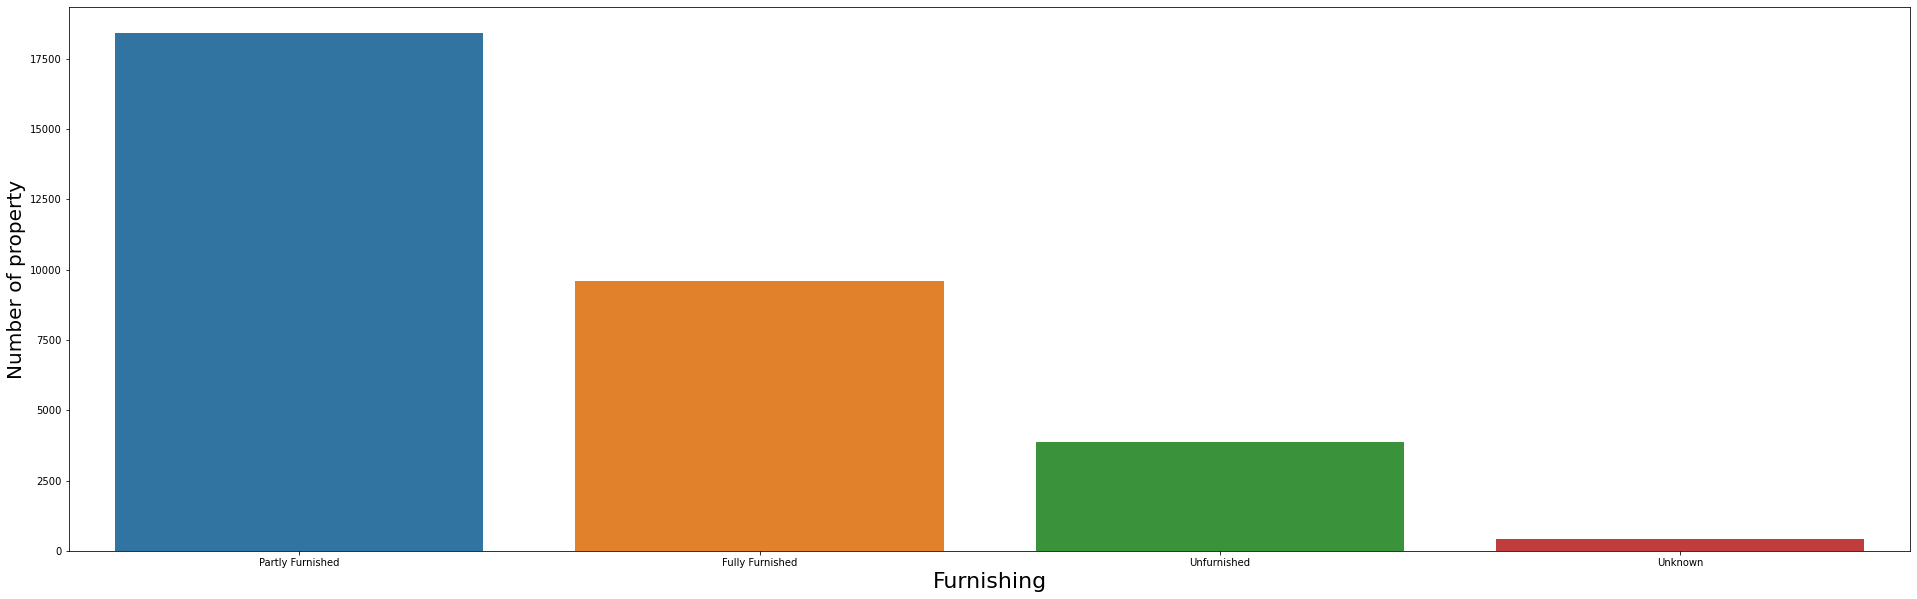

In [28]:
fig,ax=plt.subplots(figsize=(33,10))

plt.xticks(rotation='horizontal');
sns.countplot(property_kl['Furnishing'])
plt.ylabel('Number of property', fontsize = 20);
plt.xlabel('Furnishing', fontsize=22);